# 前進誤差・後退誤差・数値安定性を理解する

## 概要

前進誤差は解のずれ、後退誤差は計算結果を厳密な解にするために必要な入力のずれを測る。本記事では両者を定義し、連立一次方程式の残差と条件数を結び付ける。桁落ちとピボット選択の例をPythonで計算し、問題の性質と計算方法の性質を区別する。

## 実行環境

仮想環境は `wa-src(3.14.6)`、Pythonは `3.14.6` である。使用ライブラリのバージョンを次のセルに表示する。セルは上から実行する。小数の表示は有効数字3桁とし、計算途中では丸めない。SVGはノートブックに埋め込み、作業ディレクトリの `103_nb_files` にも保存する。

In [1]:
import sys
from decimal import Decimal, localcontext
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
assert sys.version_info[:3] == (3, 14, 6)
assert sys.prefix != sys.base_prefix
print(f"環境: wa-src({sys.version.split()[0]})")
print(f"NumPy: {np.__version__}, Matplotlib: {matplotlib.__version__}")
# SVGを保存し、未信頼のNotebookでも表示できるPNGを出力に併記する。
set_matplotlib_formats("svg", "png")
np.set_printoptions(formatter={"float_kind": lambda v: f"{v:.2e}"})
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.250,
                     "svg.fonttype": "none"})
figure_dir = Path("103_nb_files")
figure_dir.mkdir(exist_ok=True)


def latex_number(value):
    """計算値を有効数字3桁の数式にする。"""
    mantissa, exponent = f"{float(value):.2e}".split("e")
    return rf"{mantissa}\times10^{{{int(exponent)}}}"


def save_figure(fig, filename):
    """小数の目盛を整え、SVG保存と表示を行う。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if axis.get_scale() == "linear":
                axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:#.3g}"))
            axis.set_minor_formatter(NullFormatter())
    fig.savefig(figure_dir / filename, format="svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

環境: wa-src(3.14.6)
NumPy: 2.5.4, Matplotlib: 3.11.2


## 1. 前進誤差と後退誤差

入力を $a$、厳密な出力を $y=f(a)$、計算結果を $\widehat y$ とする。$a\ne0$、$y\ne0$ のとき、相対前進誤差と相対後退誤差は次式である。

<div>
$$
E_f=\frac{|\widehat y-f(a)|}{|f(a)|},\qquad
\eta=\min_{f(a+\Delta a)=\widehat y}\frac{|\Delta a|}{|a|}.
$$
</div>

絶対誤差では分母を付けない。入力や出力がゼロなら相対誤差の代わりに絶対誤差などを使う。後退誤差では、許す入力の範囲と変化の測り方を決める必要がある。対応する入力が存在しない場合もある。[Highamの解説](https://nhigham.com/2020/03/25/what-is-backward-error/)

$f(a)=a^2$、$a=1$ とし、説明用に $\widehat y=1.21$ を置く。これは丸め誤差を実測した値ではない。

$$
\begin{aligned}
E_f&=\frac{|1.21-1|}{1}=0.210,\\
(1+\Delta a)^2&=1.21,\\
1+\Delta a&=\pm1.10,\\
\Delta a&=0.100\ \text{または}\ -2.10,\\
\eta&=\min(0.100,2.10)=0.100.
\end{aligned}
$$

図の縦方向が絶対前進誤差、横方向が最小の入力の変化である。この例では分母が1なので、相対誤差と値が一致する。

<IPython.core.display.Math object>

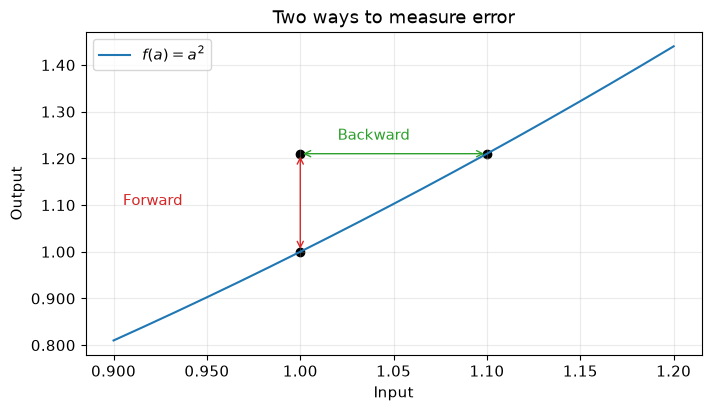

In [2]:
a = 1
y_hat = 1.21
forward = abs(y_hat - a**2) / a**2
backward = abs(np.sqrt(y_hat) - a) / abs(a)
display(Math(rf"E_f={latex_number(forward)},\quad\eta={latex_number(backward)}"))

t = np.linspace(0.900, 1.20, 200)
fig, ax = plt.subplots(layout="constrained")
ax.plot(t, t**2, label=r"$f(a)=a^2$")
ax.scatter([1, 1, 1.10], [1, 1.21, 1.21], color="black")
ax.annotate("", xy=(1, 1.21), xytext=(1, 1),
            arrowprops={"arrowstyle": "<->", "color": "tab:red"})
ax.annotate("", xy=(1.10, 1.21), xytext=(1, 1.21),
            arrowprops={"arrowstyle": "<->", "color": "tab:green"})
ax.text(0.905, 1.10, "Forward", color="tab:red")
ax.text(1.02, 1.24, "Backward", color="tab:green")
ax.set(xlabel="Input", ylabel="Output", title="Two ways to measure error")
ax.legend()
save_figure(fig, "01_error_directions.svg")

## 2. 残差から前進誤差を評価する

実数の正則な正方行列で $\mathbf{A}\mathbf{x}=\mathbf{b}$、$\mathbf{b}\ne\mathbf{0}$ とする。以下のノルムは2ノルムである。

$$
\|\mathbf{v}\|_2=\sqrt{\sum_i v_i^2},\qquad
\|\mathbf{A}\|_2=\max_{\mathbf{v}\ne\mathbf{0}}
\frac{\|\mathbf{A}\mathbf{v}\|_2}{\|\mathbf{v}\|_2}.
$$

近似解 $\widehat{\mathbf{x}}$ の残差を $\mathbf{r}=\mathbf{b}-\mathbf{A}\widehat{\mathbf{x}}$ と定義する。行列を固定し、右辺だけを変える場合、

$$
\begin{aligned}
\mathbf{A}\widehat{\mathbf{x}}&=\mathbf{b}+\Delta\mathbf{b},\\
\Delta\mathbf{b}&=\mathbf{A}\widehat{\mathbf{x}}-\mathbf{b}=-\mathbf{r},\\
\eta_b&=\frac{\|\Delta\mathbf{b}\|_2}{\|\mathbf{b}\|_2}
=\frac{\|\mathbf{r}\|_2}{\|\mathbf{b}\|_2}.
\end{aligned}
$$

したがって相対残差は、右辺だけに対する相対後退誤差である。解の誤差との関係を導く。

$$
\begin{aligned}
\mathbf{A}(\mathbf{x}-\widehat{\mathbf{x}})&=\mathbf{r},\\
\mathbf{x}-\widehat{\mathbf{x}}&=\mathbf{A}^{-1}\mathbf{r},\\
\|\mathbf{x}-\widehat{\mathbf{x}}\|_2&\le\|\mathbf{A}^{-1}\|_2\|\mathbf{r}\|_2,\\
\|\mathbf{b}\|_2&=\|\mathbf{A}\mathbf{x}\|_2\le\|\mathbf{A}\|_2\|\mathbf{x}\|_2,\\
E_f=\frac{\|\widehat{\mathbf{x}}-\mathbf{x}\|_2}{\|\mathbf{x}\|_2}
&\le\|\mathbf{A}^{-1}\|_2\|\mathbf{A}\|_2
\frac{\|\mathbf{r}\|_2}{\|\mathbf{b}\|_2}.
\end{aligned}
$$

<div>
$$
\boxed{E_f\le\kappa_2(\mathbf{A})\eta_b},\qquad
\kappa_2(\mathbf{A})=\|\mathbf{A}\|_2\|\mathbf{A}^{-1}\|_2.
$$
</div>

条件数が大きいと、小さな後退誤差だけでは小さな前進誤差を保証できない。例えば $0<\alpha\le1$ に対し、

$$
\mathbf{A}=\begin{bmatrix}1&0\\0&\alpha\end{bmatrix},\quad
\mathbf{b}=\begin{bmatrix}1\\0\end{bmatrix},\quad
\mathbf{x}=\begin{bmatrix}1\\0\end{bmatrix},\quad
\widehat{\mathbf{x}}=\begin{bmatrix}1\\1\end{bmatrix}
$$

と置くと、$\mathbf{r}=(0,-\alpha)^{\mathsf T}$ であり、$\eta_b=\alpha$、$\kappa_2=1/\alpha$、$E_f=1$ となる。近似解は意図的に作ったもので、`solve` の出力ではない。

各列: 条件数、右辺の後退誤差、前進誤差
array([[1.00e+12, 1.00e-12, 1.00e+00],
       [1.00e+06, 1.00e-06, 1.00e+00],
       [1.00e+00, 1.00e+00, 1.00e+00]])


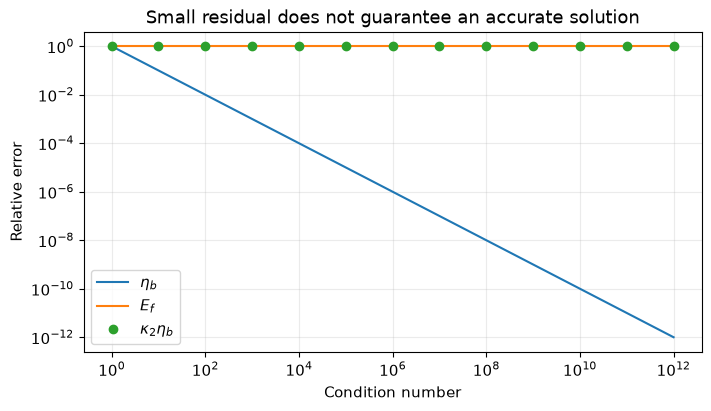

In [3]:
alphas = np.logspace(-12, 0, 49)
b = np.array([1, 0], dtype=float)
x_true = b.copy()
x_hat = np.array([1, 1], dtype=float)
records = []
for alpha in alphas:
    A = np.diag([1, alpha])
    eta_b = np.linalg.norm(b - A @ x_hat) / np.linalg.norm(b)
    error = np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)
    records.append([np.linalg.cond(A), eta_b, error])
records = np.array(records)
print("各列: 条件数、右辺の後退誤差、前進誤差")
pprint(records[[0, 24, -1]])
fig, ax = plt.subplots(layout="constrained")
ax.loglog(records[:, 0], records[:, 1], label=r"$\eta_b$")
ax.loglog(records[:, 0], records[:, 2], label=r"$E_f$")
ax.loglog(records[::4, 0], (records[:, 0] * records[:, 1])[::4],
          "o", label=r"$\kappa_2\eta_b$")
ax.set(xlabel="Condition number", ylabel="Relative error",
       title="Small residual does not guarantee an accurate solution")
ax.legend()
save_figure(fig, "02_residual_and_condition.svg")

### 行列と右辺を両方変える後退誤差

$\mathbf{A}$ と $\mathbf{b}$ の両方に変化を許す場合もよく使う。

$$
\eta_{A,b}=\min\{\epsilon\ge0:
(\mathbf{A}+\Delta\mathbf{A})\widehat{\mathbf{x}}=\mathbf{b}+\Delta\mathbf{b},\quad
\|\Delta\mathbf{A}\|_2\le\epsilon\|\mathbf{A}\|_2,\quad
\|\Delta\mathbf{b}\|_2\le\epsilon\|\mathbf{b}\|_2\}.
$$

$D=\|\mathbf{A}\|_2\|\widehat{\mathbf{x}}\|_2+\|\mathbf{b}\|_2$ と置く。残差は $\mathbf{r}=\Delta\mathbf{A}\widehat{\mathbf{x}}-\Delta\mathbf{b}$ なので、三角不等式から $\|\mathbf{r}\|_2\le\epsilon D$ となる。つまり $\epsilon\ge\|\mathbf{r}\|_2/D$ が必要である。

この下限は達成できる。$\mathbf{r}\ne\mathbf{0}$、$\widehat{\mathbf{x}}\ne\mathbf{0}$ とし、$\mathbf{v}=\mathbf{r}/\|\mathbf{r}\|_2$、$\mathbf{z}=\widehat{\mathbf{x}}/\|\widehat{\mathbf{x}}\|_2$、$\epsilon=\|\mathbf{r}\|_2/D$ と置けば、

$$
\begin{aligned}
\Delta\mathbf{A}&=\epsilon\|\mathbf{A}\|_2\mathbf{v}\mathbf{z}^{\mathsf T},\quad
\Delta\mathbf{b}=-\epsilon\|\mathbf{b}\|_2\mathbf{v},\\
\Delta\mathbf{A}\widehat{\mathbf{x}}-\Delta\mathbf{b}
&=\epsilon(\|\mathbf{A}\|_2\|\widehat{\mathbf{x}}\|_2+\|\mathbf{b}\|_2)\mathbf{v}
=\mathbf{r}.
\end{aligned}
$$

単位ベクトル同士なので $\|\mathbf{v}\mathbf{z}^{\mathsf T}\|_2=1$ であり、両方のノルム条件も満たす。よって、

<div>
$$
\boxed{\eta_{A,b}=\frac{\|\mathbf{r}\|_2}
{\|\mathbf{A}\|_2\|\widehat{\mathbf{x}}\|_2+\|\mathbf{b}\|_2}}.
$$
</div>

残差がゼロなら両方の変化をゼロにできる。近似解がゼロなら右辺をゼロに変えればよく、同じ式が成り立つ。これはノルム単位の評価であり、各成分の相対変化を制限する評価とは異なる。$\eta_b$ と定義が違うため、先ほどの上界へそのまま代入しない。

## 3. 数値安定性と桁落ち

最近接丸めの基本演算は、オーバーフローやアンダーフローなどを除くと、$\operatorname{fl}(a\circ b)=(a\circ b)(1+\delta)$、$|\delta|\le u$ とモデル化できる。binary64の単位丸め誤差は $u=2^{-53}\approx1.11\times10^{-16}$ である。`np.finfo(float).eps` は $2u$ に相当する。

対象となる入力に対して後退誤差を $C u$ 程度に抑える方法を後退安定と呼ぶ。$C$ は問題の大きさなどに依存する係数である。数値安定性には前進安定などの定義もあるが、ここでは後退安定性を中心に扱う。条件数は問題の感度であり、安定性は計算方法の性質である。

### 引き算を含む同じ式を比較する

$t>0$ に対して $f(t)=\sqrt{1+t}-1$ を考える。小さな $t$ では、平方根までの誤差が引き算の後に相対的に大きくなる。有理化すると次式になる。

$$
\begin{aligned}
f(t)&=\frac{(\sqrt{1+t}-1)(\sqrt{1+t}+1)}{\sqrt{1+t}+1}\\
&=\frac{(1+t)-1}{\sqrt{1+t}+1}
=\frac{t}{\sqrt{1+t}+1}.
\end{aligned}
$$

この問題自体の相対条件数を計算する。

$$
\begin{aligned}
f'(t)&=\frac{1}{2\sqrt{1+t}},\\
\kappa_f(t)&=\left|\frac{tf'(t)}{f(t)}\right|
=\frac{t}{2\sqrt{1+t}(\sqrt{1+t}-1)}\\
&=\frac{\sqrt{1+t}+1}{2\sqrt{1+t}}\longrightarrow1\quad(t\to0^+).
\end{aligned}
$$

入力に対する感度は大きくない。精度が落ちる原因は計算方法にある。比較の基準値は、格納済みの浮動小数点入力を正確にDecimalへ移し、80桁の精度で有理化した式を計算する。数学的な厳密値そのものではないが、binary64の誤差を見るには十分である。

各列: 入力、直接計算、有理化、直接計算の相対誤差、有理化の相対誤差
array([[1.00e-18, 0.00e+00, 5.00e-19, 1.00e+00, 2.50e-19],
       [3.73e-10, 1.86e-10, 1.86e-10, 5.77e-07, 2.89e-17],
       [1.00e-01, 4.88e-02, 4.88e-02, 1.66e-15, 4.32e-17]])


<IPython.core.display.Math object>

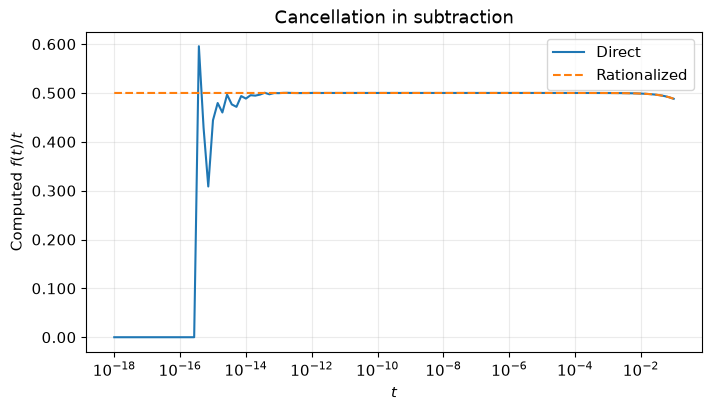

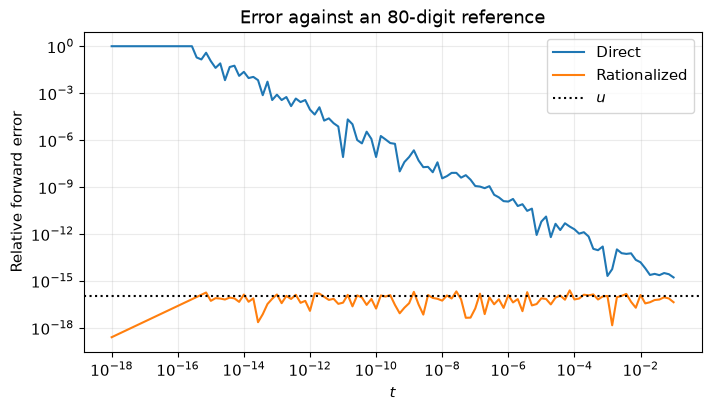

In [4]:
ts = np.logspace(-18, -1, 120)
direct = np.sqrt(1 + ts) - 1
rationalized = ts / (np.sqrt(1 + ts) + 1)
errors = []
with localcontext() as ctx:
    ctx.prec = 80
    for t, y1, y2 in zip(ts, direct, rationalized):
        d = Decimal.from_float(float(t))
        reference = d / ((1 + d).sqrt() + 1)
        errors.append([float(abs(Decimal.from_float(float(y)) - reference) / reference)
                       for y in (y1, y2)])
errors = np.array(errors)
u = np.finfo(float).eps / 2
print("各列: 入力、直接計算、有理化、直接計算の相対誤差、有理化の相対誤差")
pprint(np.column_stack([ts, direct, rationalized, errors])[[0, 60, -1]])
display(Math(rf"u={latex_number(u)}"))

# tで割ると、ゼロに丸められた出力も線形の縦軸で確認できる。
fig, ax = plt.subplots(layout="constrained")
ax.semilogx(ts, direct / ts, label="Direct")
ax.semilogx(ts, rationalized / ts, "--", label="Rationalized")
ax.set(xlabel=r"$t$", ylabel=r"Computed $f(t)/t$", title="Cancellation in subtraction")
ax.legend()
save_figure(fig, "03_cancellation_values.svg")

fig, ax = plt.subplots(layout="constrained")
ax.loglog(ts, errors[:, 0], label="Direct")
ax.loglog(ts, errors[:, 1], label="Rationalized")
ax.axhline(u, color="black", linestyle=":", label=r"$u$")
ax.set(xlabel=r"$t$", ylabel="Relative forward error", title="Error against an 80-digit reference")
ax.legend()
save_figure(fig, "04_cancellation_errors.svg")

小さな入力では直接計算がゼロを返し、前進誤差が1になる。有理化した計算の誤差はこの範囲では $u$ 程度である。私は、このように条件数と計算順序を分けて確認する方が原因を整理しやすいと感じる。なお、有限個の実験だけでは後退安定性の証明にはならない。

## 4. ピボット選択で結果が変わる例

$0<\tau<1$ とし、次の連立一次方程式を解く。

$$
\mathbf{A}=\begin{bmatrix}\tau&1\\1&1\end{bmatrix},\qquad
\mathbf{b}=\begin{bmatrix}1\\2\end{bmatrix}.
$$

第2式から $x_2=2-x_1$ である。第1式に代入すると、$\tau x_1+2-x_1=1$、$(1-\tau)x_1=1$ なので、

$$
x_1=\frac{1}{1-\tau},\qquad
x_2=2-\frac{1}{1-\tau}=\frac{1-2\tau}{1-\tau}.
$$

行を入れ替えない消去法では、第1行の $m=1/\tau$ 倍を第2行から引く。

$$
\begin{aligned}
(1-m\tau)x_1+(1-m)x_2&=2-m,\\
(1-m)x_2&=2-m,\\
x_2&=\frac{2-m}{1-m},\\
x_1&=\frac{1-x_2}{\tau}.
\end{aligned}
$$

$\tau$ が小さいと大きな $m$ が発生し、最後の引き算の誤差も $1/\tau$ 倍される。行を入れ替える部分ピボット選択なら最初のピボットは1、倍率は $\tau$ となる。比較に使う [`np.linalg.solve`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html) はLAPACKのGESVを呼び、[部分ピボット選択によるLU分解](https://netlib.org/lapack/lapack-3.1.1/html/dgesv.f.html)を用いる。

前進誤差の基準解と残差はDecimalの80桁精度で評価する。同じ精度で残差を計算すると丸めによってゼロになり、誤差を見落とす場合があるためである。

条件数の最小値と最大値
array([2.62e+00, 2.65e+00])
各列: tau、行交換なしの前進・後退誤差、solveの前進・後退誤差
array([[1.00e-18, 7.07e-01, 2.59e-01, 1.00e-18, 2.21e-19],
       [1.00e-10, 5.84e-08, 1.83e-08, 8.26e-18, 1.83e-18],
       [1.00e-02, 3.25e-15, 1.01e-15, 1.16e-16, 2.64e-17]])


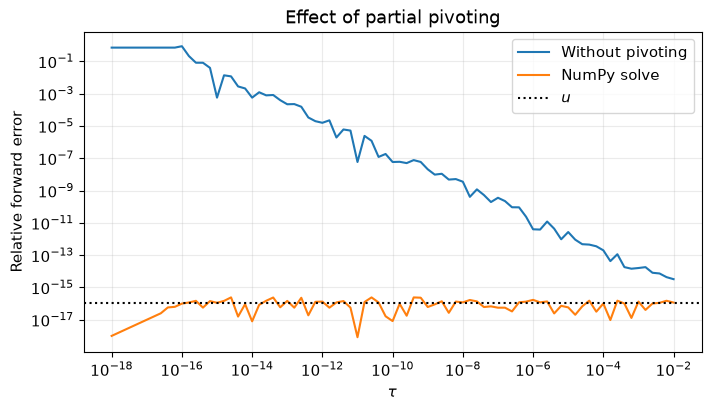

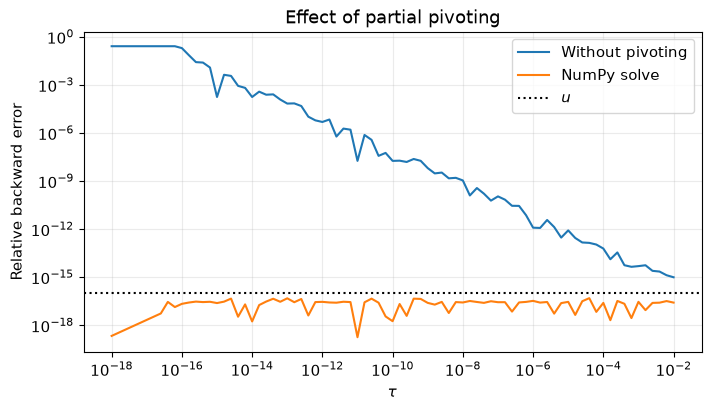

In [5]:
def assess(tau, A, b, x_hat):
    """格納済みの入力に対する基準解・残差を高精度で計算する。"""
    with localcontext() as ctx:
        ctx.prec = 80
        d = Decimal.from_float(float(tau))
        z = [Decimal.from_float(float(v)) for v in x_hat]
        ref = [1 / (1 - d), (1 - 2 * d) / (1 - d)]
        forward = (sum((v - w)**2 for v, w in zip(z, ref))
                   / sum(w**2 for w in ref)).sqrt()
        residual = ((1 - d * z[0] - z[1])**2 + (2 - z[0] - z[1])**2).sqrt()
    scale = np.linalg.norm(A, 2) * np.linalg.norm(x_hat) + np.linalg.norm(b)
    return float(forward), float(residual) / scale


taus = np.logspace(-18, -2, 81)
no_pivot, pivot, conditions = [], [], []
for tau in taus:
    A = np.array([[tau, 1], [1, 1]])
    b = np.array([1, 2], dtype=float)
    # 2次元の消去法を、そのまま式の順に実装する。
    multiplier = 1 / tau
    x2 = (2 - multiplier) / (1 - multiplier)
    naive = np.array([(1 - x2) / tau, x2])
    solved = np.linalg.solve(A, b)
    no_pivot.append(assess(tau, A, b, naive))
    pivot.append(assess(tau, A, b, solved))
    conditions.append(np.linalg.cond(A))
no_pivot, pivot = np.array(no_pivot), np.array(pivot)
print("条件数の最小値と最大値")
pprint(np.array([min(conditions), max(conditions)]))
print("各列: tau、行交換なしの前進・後退誤差、solveの前進・後退誤差")
pprint(np.column_stack([taus, no_pivot, pivot])[[0, 40, -1]])

for column, ylabel, filename in [
    (0, "Relative forward error", "05_pivot_forward.svg"),
    (1, "Relative backward error", "06_pivot_backward.svg"),
]:
    fig, ax = plt.subplots(layout="constrained")
    ax.loglog(taus, no_pivot[:, column], label="Without pivoting")
    ax.loglog(taus, pivot[:, column], label="NumPy solve")
    ax.axhline(u, color="black", linestyle=":", label=r"$u$")
    ax.set(xlabel=r"$\tau$", ylabel=ylabel, title="Effect of partial pivoting")
    ax.legend()
    save_figure(fig, filename)

この範囲の条件数は約 $2.62$ から $2.65$ であり、問題自体の感度は大きくない。それでも行交換なしでは前進誤差と後退誤差が大きくなる。部分ピボット選択はこの例では有効である。ただし一般には消去中の要素の増大にも誤差が依存し、どの行列でも同じ精度になるとは限らない。

## 結論

この記事では、前進誤差が解のずれを、後退誤差が入力のずれを測り、条件数と計算方法の安定性を合わせて精度を判断することを説明した。

残差が小さいだけでは解の正確さは分からない。何を変えてよいかを決めて後退誤差を求め、条件数と照合する。条件数が小さいのに誤差が大きい場合は、桁落ちやピボット選択などの計算過程を確認する。

参考文献として、Higham, *Accuracy and Stability of Numerical Algorithms*, 第2版、SIAM、2002年の第1・7・9章がある。定義と実装の資料は本文中にリンクした。